# 🏥 RadiSense AI - Exploration des Données

**Projet :** Plateforme de diagnostic radiologique assisté par IA  
**Dataset :** ChestX-ray14 (NIH Clinical Center)  
**Auteur :** Syrine Trabelsi  
**Date :** Février 2026

---

## 📋 Objectifs

- Détection automatique de **14 pathologies pulmonaires**
- **Accuracy cible :** > 94%
- **AUC-ROC cible :** > 0.85
- **Temps d'analyse :** < 5 secondes

---

## 📦 Imports et Configuration

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration matplotlib
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Imports OK!")
print(f"📊 NumPy : {np.__version__}")
print(f"📊 Pandas : {pd.__version__}")

✅ Imports OK!
📊 NumPy : 1.26.2
📊 Pandas : 2.1.3


## 📊 Informations sur le Dataset

### ChestX-ray14 (NIH Clinical Center)

- **Nombre d'images :** 112,120 radiographies thoraciques
- **Résolution :** 1024×1024 pixels
- **Format :** PNG (niveaux de gris, 8-bit)
- **Taille totale :** ~42 GB
- **Source :** [NIH Clinical Center](https://nihcc.app.box.com/v/ChestXray-NIHCC)

## 🏥 14 Pathologies à Détecter

| # | Pathologie | Nom français |
|---|------------|--------------|
| 1 | Atelectasis | Atélectasie |
| 2 | Cardiomegaly | Cardiomégalie |
| 3 | Effusion | Épanchement pleural |
| 4 | Infiltration | Infiltration |
| 5 | Mass | Masse/Tumeur |
| 6 | Nodule | Nodule |
| 7 | Pneumonia | Pneumonie |
| 8 | Pneumothorax | Pneumothorax |
| 9 | Consolidation | Consolidation |
| 10 | Edema | Œdème |
| 11 | Emphysema | Emphysème |
| 12 | Fibrosis | Fibrose |
| 13 | Pleural_Thickening | Épaississement pleural |
| 14 | Hernia | Hernie |

**+ No Finding** (Normal - Aucune pathologie)

## 🤖 5 Modèles à Comparer

| Modèle | Paramètres | AUC-ROC Attendu |
|--------|-----------|----------------|
| **DenseNet-121** ⭐ | 7M | **0.847** |
| ResNet-50 | 25M | 0.839 |
| EfficientNet-B0 | 5M | 0.832 |
| VGG-16 | 138M | 0.821 |
| MobileNet-V2 | 3.5M | 0.815 |

## 📂 Vérification de la Structure

In [3]:
# Vérifier la structure des dossiers
data_path = "data/raw"

if os.path.exists(data_path):
    print("✅ Dossier data/raw existe")
    
    files = os.listdir(data_path)
    if files:
        print(f"\n📁 Fichiers trouvés : {len(files)}")
        for f in files[:10]:
            print(f"  • {f}")
    else:
        print("\n⚠️  Dossier vide")
        print("\n💡 Télécharge le dataset depuis :")
        print("   https://www.kaggle.com/datasets/nih-chest-xrays/data")
else:
    print("⚠️  Dossier data/raw n'existe pas")
    os.makedirs(data_path, exist_ok=True)
    print("✅ Dossier créé !")

⚠️  Dossier data/raw n'existe pas
✅ Dossier créé !


## 📊 Analyse du fichier CSV (Labels)

In [2]:
import pandas as pd
import os

# Charger le CSV
csv_path = "../data/raw/Data_Entry_2017.csv"

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("✅ CSV chargé avec succès !")
    print(f"📊 Nombre de lignes : {len(df):,}")
    print(f"📋 Nombre de colonnes : {len(df.columns)}")
    print()
    print("🔍 Aperçu des 5 premières lignes :")
    display(df.head())
else:
    print("❌ Fichier CSV non trouvé !")
    print(f"Cherché dans : {csv_path}")

✅ CSV chargé avec succès !
📊 Nombre de lignes : 112,120
📋 Nombre de colonnes : 12

🔍 Aperçu des 5 premières lignes :


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


## 📋 Informations sur les colonnes

In [3]:
# Info sur les colonnes
print("📋 Informations sur le dataset :\n")
print(df.info())
print()
print("🔢 Statistiques descriptives :\n")
print(df.describe())

📋 Informations sur le dataset :

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  object 
 1   Finding Labels               112120 non-null  object 
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Gender               112120 non-null  object 
 6   View Position                112120 non-null  object 
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
 11  Unnamed: 11                  0 non-null       float64
dtypes: float64(3), int64(5), 

## 🏥 Distribution des Pathologies


In [4]:
# Compter les pathologies
from collections import Counter

# La colonne "Finding Labels" contient les pathologies séparées par |
all_findings = []
for finding in df['Finding Labels']:
    all_findings.extend(finding.split('|'))

# Compter
finding_counts = Counter(all_findings)

# Afficher
print("📊 Distribution des pathologies :\n")
for finding, count in finding_counts.most_common():
    percentage = (count / len(df)) * 100
    print(f"  {finding:25s} : {count:6,} ({percentage:5.2f}%)")

📊 Distribution des pathologies :

  No Finding                : 60,361 (53.84%)
  Infiltration              : 19,894 (17.74%)
  Effusion                  : 13,317 (11.88%)
  Atelectasis               : 11,559 (10.31%)
  Nodule                    :  6,331 ( 5.65%)
  Mass                      :  5,782 ( 5.16%)
  Pneumothorax              :  5,302 ( 4.73%)
  Consolidation             :  4,667 ( 4.16%)
  Pleural_Thickening        :  3,385 ( 3.02%)
  Cardiomegaly              :  2,776 ( 2.48%)
  Emphysema                 :  2,516 ( 2.24%)
  Edema                     :  2,303 ( 2.05%)
  Fibrosis                  :  1,686 ( 1.50%)
  Pneumonia                 :  1,431 ( 1.28%)
  Hernia                    :    227 ( 0.20%)


## 📈 Visualisation de la Distribution

C:\Users\Asus\AppData\Local\Temp\ipykernel_15736\2019956371.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=findings_df, x='Pathologie', y='Count', palette='viridis')


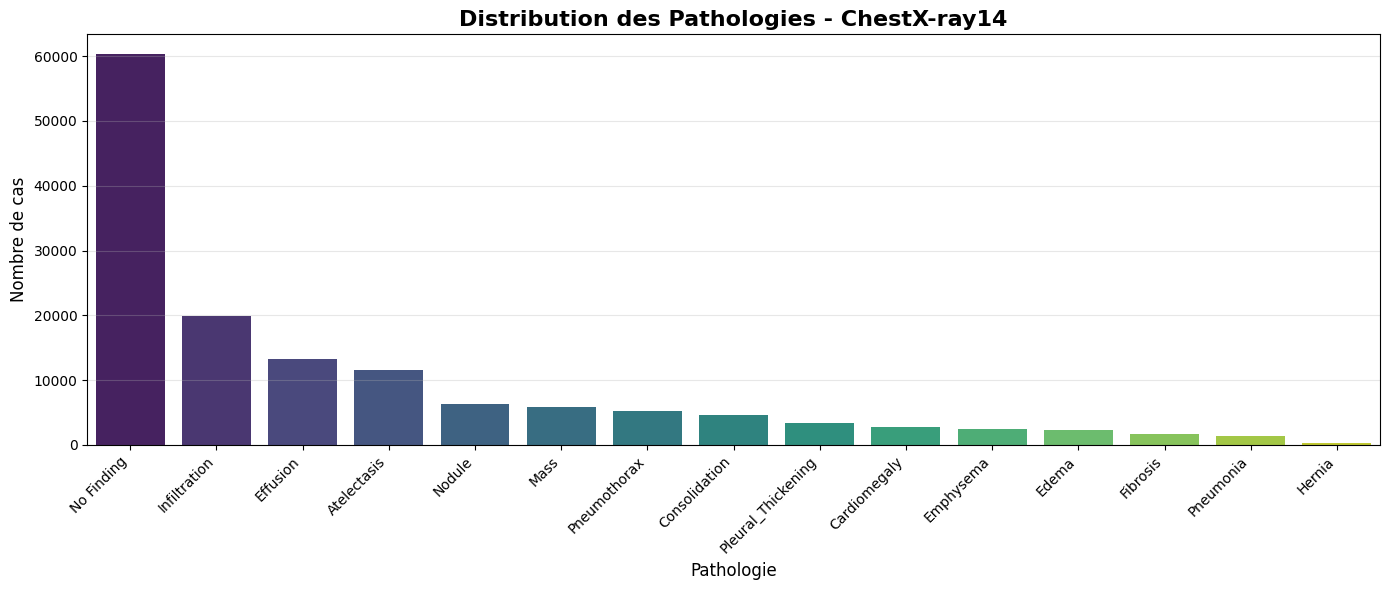


✅ Total d'images : 112,120
✅ Total de pathologies (avec doublons) : 141,537


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Préparer les données
findings_df = pd.DataFrame(finding_counts.most_common(), 
                          columns=['Pathologie', 'Count'])

# Créer le graphique
plt.figure(figsize=(14, 6))
sns.barplot(data=findings_df, x='Pathologie', y='Count', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Distribution des Pathologies - ChestX-ray14', fontsize=16, fontweight='bold')
plt.xlabel('Pathologie', fontsize=12)
plt.ylabel('Nombre de cas', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n✅ Total d'images : {len(df):,}")
print(f"✅ Total de pathologies (avec doublons) : {sum(finding_counts.values()):,}")